# Next-Day Wildfire Spread — Advanced Model (Attention U-Net)

**Task:** given 12 daily maps (weather, vegetation, terrain, population, previous fire mask) on a 64x64 grid, predict where fire will be **tomorrow** (per-pixel segmentation).

**What is improved over the baseline CNN**

| Baseline notebook | This notebook |
|---|---|
| Plain 4-layer CNN, no downsampling (tiny receptive field) | Attention U-Net with residual blocks (multi-scale context) |
| `FireMask = -1` (unlabeled) pixels treated as a label, which makes the loss negative | Unlabeled pixels are masked out of loss and metrics |
| Weighted BCE (fixed weight 10) | Focal loss + Dice loss (handles ~1% fire pixels) |
| Python generator, about 1000 s per epoch | Native `tf.io.parse_single_example` pipeline (much faster) |
| Precision/recall at 0.5 only | AUC-PR, F1, IoU, tuned threshold, compared against a persistence baseline |

In [ ]:
import os, glob, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model
from sklearn.metrics import average_precision_score

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR  = '/content/drive/MyDrive/Colab Notebooks/23it551'
OUT_DIR   = '/content/drive/MyDrive/Colab Notebooks/wildfire_outputs'
os.makedirs(OUT_DIR, exist_ok=True)

all_files   = sorted(glob.glob(os.path.join(DATA_DIR, '*.tfrecord')))
train_files = [f for f in all_files if '_train_' in f]
eval_files  = [f for f in all_files if '_eval_'  in f]
test_files  = [f for f in all_files if '_test_'  in f]
print(len(train_files), 'train |', len(eval_files), 'eval |', len(test_files), 'test files')

Mounted at /content/drive
15 train | 2 eval | 2 test files


## 1. Configuration and fast TFRecord parsing

In [ ]:
SIZE = 64
# PrevFireMask MUST stay last: it is handled separately from the continuous channels
CONT_FEATURES = ['elevation','th','vs','tmmn','tmmx','sph','pr','pdsi','NDVI','population','erc']
FEATURES = CONT_FEATURES + ['PrevFireMask']
N_CONT = len(CONT_FEATURES)
N_CHANNELS = N_CONT + 2          # 11 continuous + prev-fire + prev-fire-unknown
BATCH = 32
EPOCHS = 30
AUGMENT = True

def parse_fn(serialized):
    spec = {k: tf.io.FixedLenFeature([SIZE*SIZE], tf.float32) for k in FEATURES + ['FireMask']}
    ex = tf.io.parse_single_example(serialized, spec)
    x = tf.stack([tf.reshape(ex[k], (SIZE, SIZE)) for k in FEATURES], axis=-1)   # 64x64x12
    y = tf.reshape(ex['FireMask'], (SIZE, SIZE, 1))
    return x, y

def raw_ds(files):
    return tf.data.TFRecordDataset(files, num_parallel_reads=tf.data.AUTOTUNE).map(
        parse_fn, num_parallel_calls=tf.data.AUTOTUNE)

In [ ]:
print("DATA_DIR exists:", os.path.exists(DATA_DIR))
print("OUT_DIR exists :", os.path.exists(OUT_DIR))
print("train / eval / test files:", len(train_files), len(eval_files), len(test_files))
print(train_files[:2])



DATA_DIR exists: True
OUT_DIR exists : True
train / eval / test files: 15 2 2
['/content/drive/MyDrive/Colab Notebooks/23it551/next_day_wildfire_spread_train_00.tfrecord', '/content/drive/MyDrive/Colab Notebooks/23it551/next_day_wildfire_spread_train_01.tfrecord']


In [ ]:
import shutil

LOCAL_DIR = '/content/wildfire_data'
os.makedirs(LOCAL_DIR, exist_ok=True)

# 1) copy from Drive to local disk (skips files already copied)
for f in all_files:
    dst = os.path.join(LOCAL_DIR, os.path.basename(f))
    if not os.path.exists(dst):
        shutil.copy(f, dst)
        print('copied', os.path.basename(f))

# 2) re-glob from the local copy
DATA_DIR    = LOCAL_DIR
all_files   = sorted(glob.glob(os.path.join(DATA_DIR, '*.tfrecord')))
train_files = [f for f in all_files if '_train_' in f]
eval_files  = [f for f in all_files if '_eval_'  in f]
test_files  = [f for f in all_files if '_test_'  in f]

# 3) verify every file opens and has records
for f in all_files:
    n = sum(1 for _ in tf.data.TFRecordDataset(f).take(5))
    print(os.path.basename(f), '->', 'OK' if n > 0 else 'EMPTY', f'({os.path.getsize(f)/1e6:.0f} MB)')

copied next_day_wildfire_spread_eval_00.tfrecord
copied next_day_wildfire_spread_eval_01.tfrecord
copied next_day_wildfire_spread_test_00.tfrecord
copied next_day_wildfire_spread_test_01.tfrecord
copied next_day_wildfire_spread_train_00.tfrecord
copied next_day_wildfire_spread_train_01.tfrecord
copied next_day_wildfire_spread_train_02.tfrecord
copied next_day_wildfire_spread_train_03.tfrecord
copied next_day_wildfire_spread_train_04.tfrecord
copied next_day_wildfire_spread_train_05.tfrecord
copied next_day_wildfire_spread_train_06.tfrecord
copied next_day_wildfire_spread_train_07.tfrecord
copied next_day_wildfire_spread_train_08.tfrecord
copied next_day_wildfire_spread_train_09.tfrecord
copied next_day_wildfire_spread_train_10.tfrecord
copied next_day_wildfire_spread_train_11.tfrecord
copied next_day_wildfire_spread_train_12.tfrecord
copied next_day_wildfire_spread_train_13.tfrecord
copied next_day_wildfire_spread_train_14.tfrecord
next_day_wildfire_spread_eval_00.tfrecord -> OK (213 M

## 2. Normalization statistics (train set only)
NaNs are ignored when computing the statistics. Stats are cached to Drive so you only compute them once.

In [ ]:
stats_path = os.path.join(OUT_DIR, 'norm_stats.npz')

if os.path.exists(stats_path):
    d = np.load(stats_path); mean, std = d['mean'], d['std']
else:
    s = np.zeros(N_CONT); s2 = np.zeros(N_CONT); n = np.zeros(N_CONT)
    for x, _ in raw_ds(train_files).take(5000).batch(256):
        c = x.numpy()[..., :N_CONT].astype(np.float64)
        f = np.isfinite(c)
        c = np.where(f, c, 0.0)
        s += c.sum((0,1,2)); s2 += (c**2).sum((0,1,2)); n += f.sum((0,1,2))
    mean = s / n
    std  = np.sqrt(np.maximum(s2 / n - mean**2, 1e-8))
    np.savez(stats_path, mean=mean, std=std)

for k, m, sd in zip(CONT_FEATURES, mean, std):
    print(f'{k:11s} mean={m:12.4f} std={sd:12.4f}')

MEAN = tf.constant(mean, tf.float32)
STD  = tf.constant(std,  tf.float32)

elevation   mean=    934.5195 std=    848.5537
th          mean=     99.9088 std=   4799.5877
vs          mean=      3.5790 std=      1.2952
tmmn        mean=    282.3179 std=     16.9881
tmmx        mean=    298.0588 std=     17.8679
sph         mean=      0.0065 std=      0.0037
pr          mean=      0.3224 std=      1.5497
pdsi        mean=     -0.9414 std=      2.4169
NDVI        mean=   5323.1637 std=   2186.6735
population  mean=     28.6536 std=    211.9502
erc         mean=     54.6264 std=     25.7806


## 3. Preprocessing and augmentation
* NaN becomes the channel mean (0 after normalization); values clipped to +-5 std (NDVI and population have outliers).
* `PrevFireMask` becomes 2 channels: fire (1/0) and unknown (`-1` in the raw data).
* Target becomes 2 channels: `[fire label, valid mask]`. Valid = pixel was not `-1` (unlabeled/cloud).
* Augmentation (train only): random flips / 90-degree rotations applied to inputs and target together. Note: this makes the wind-direction (`th`) channel slightly inconsistent; set `AUGMENT = False` to compare.

In [ ]:
def preprocess(x, y):
    cont = x[..., :N_CONT]
    cont = tf.where(tf.math.is_finite(cont), cont, MEAN)
    cont = tf.clip_by_value((cont - MEAN) / STD, -5.0, 5.0)

    prev = x[..., N_CONT:N_CONT+1]
    prev = tf.where(tf.math.is_finite(prev), prev, tf.zeros_like(prev))
    prev_fire = tf.cast(prev > 0.5, tf.float32)
    prev_unk  = tf.cast(prev < -0.5, tf.float32)

    inp = tf.concat([cont, prev_fire, prev_unk], axis=-1)           # 64x64x13

    label = tf.cast(y > 0.5, tf.float32)
    valid = tf.cast(y > -0.5, tf.float32)
    return inp, tf.concat([label, valid], axis=-1)                   # 64x64x2

def augment(x, y):
    both = tf.concat([x, y], axis=-1)
    both = tf.image.random_flip_left_right(both)
    both = tf.image.random_flip_up_down(both)
    both = tf.image.rot90(both, k=tf.random.uniform([], 0, 4, tf.int32))
    return both[..., :N_CHANNELS], both[..., N_CHANNELS:]

def make_ds(files, training):
    ds = raw_ds(files)
    if training:
        ds = ds.shuffle(2000, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    if training and AUGMENT:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train_files, True)
eval_ds  = make_ds(eval_files,  False)
test_ds  = make_ds(test_files,  False)

xb, yb = next(iter(train_ds))
print('Input batch :', xb.shape, '| Target batch:', yb.shape)
print('Fire pixels among valid ones: %.3f%%' % (100 * yb[...,0].numpy().sum() / yb[...,1].numpy().sum()))

Input batch : (32, 64, 64, 13) | Target batch: (32, 64, 64, 2)
Fire pixels among valid ones: 1.016%


## 4. Loss and metrics (mask-aware)
Focal loss down-weights easy "no fire" pixels; Dice loss directly optimises overlap. Both ignore unlabeled pixels.

In [ ]:
EPS = 1e-7

def masked_focal_dice_loss(y_true, y_pred, gamma=2.0, alpha=0.75, dice_weight=1.0):
    y = y_true[..., 0:1]
    m = y_true[..., 1:2]
    p = tf.clip_by_value(y_pred, EPS, 1.0 - EPS)

    pt = y * p + (1.0 - y) * (1.0 - p)
    a  = y * alpha + (1.0 - y) * (1.0 - alpha)
    focal = -a * tf.pow(1.0 - pt, gamma) * tf.math.log(pt)
    focal = tf.reduce_sum(focal * m) / (tf.reduce_sum(m) + EPS)

    inter =  tf.reduce_sum(p * y * m, axis=(1, 2, 3))
    denom = tf.reduce_sum((p + y) * m, axis=(1, 2, 3))
    dice  = 1.0 - (2.0 * inter + 1.0) / (denom + 1.0)
    return focal + dice_weight * tf.reduce_mean(dice)


class MaskedAUCPR(tf.keras.metrics.AUC):
    def __init__(self, name='auc_pr', **kw):
        super().__init__(curve='PR', name=name, **kw)
    def update_state(self, y_true, y_pred, sample_weight=None):
        return super().update_state(y_true[..., 0:1], y_pred, sample_weight=y_true[..., 1:2])

class MaskedPrecision(tf.keras.metrics.Precision):
    def __init__(self, name='precision', **kw):
        super().__init__(thresholds=0.5, name=name, **kw)
    def update_state(self, y_true, y_pred, sample_weight=None):
        return super().update_state(y_true[..., 0:1], y_pred, sample_weight=y_true[..., 1:2])

class MaskedRecall(tf.keras.metrics.Recall):
    def __init__(self, name='recall', **kw):
        super().__init__(thresholds=0.5, name=name, **kw)
    def update_state(self, y_true, y_pred, sample_weight=None):
        return super().update_state(y_true[..., 0:1], y_pred, sample_weight=y_true[..., 1:2])

## 5. Model: Residual Attention U-Net
* Encoder: 3 residual blocks with max-pooling (64 to 32 to 16 to 8 resolution) so the network sees wide context (wind and terrain effects).
* Attention gates on skip connections: the decoder tells the skip features which regions matter.
* Output: per-pixel fire probability for tomorrow.

In [ ]:
def res_block(x, filters, drop=0.0):
    shortcut = layers.Conv2D(filters, 1, padding='same')(x)
    y = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    y = layers.BatchNormalization()(y); y = layers.Activation('relu')(y)
    y = layers.Conv2D(filters, 3, padding='same', use_bias=False)(y)
    y = layers.BatchNormalization()(y)
    y = layers.Add()([y, shortcut]); y = layers.Activation('relu')(y)
    if drop > 0: y = layers.SpatialDropout2D(drop)(y)
    return y

def attention_gate(skip, gate, inter):
    theta = layers.Conv2D(inter, 1, padding='same')(skip)
    phi   = layers.Conv2D(inter, 1, padding='same')(gate)
    f     = layers.Activation('relu')(layers.Add()([theta, phi]))
    psi   = layers.Conv2D(1, 1, padding='same', activation='sigmoid')(f)
    return layers.Multiply()([skip, psi])

def build_attention_unet(input_shape=(SIZE, SIZE, N_CHANNELS), base=32):
    inp = layers.Input(input_shape)

    e1 = res_block(inp, base)                                   # 64x64
    e2 = res_block(layers.MaxPooling2D()(e1), base * 2)         # 32x32
    e3 = res_block(layers.MaxPooling2D()(e2), base * 4)         # 16x16
    b  = res_block(layers.MaxPooling2D()(e3), base * 8, 0.2)    # 8x8

    d3 = layers.UpSampling2D(interpolation='bilinear')(b)
    d3 = layers.Concatenate()([d3, attention_gate(e3, d3, base * 2)])
    d3 = res_block(d3, base * 4)

    d2 = layers.UpSampling2D(interpolation='bilinear')(d3)
    d2 = layers.Concatenate()([d2, attention_gate(e2, d2, base)])
    d2 = res_block(d2, base * 2)

    d1 = layers.UpSampling2D(interpolation='bilinear')(d2)
    d1 = layers.Concatenate()([d1, attention_gate(e1, d1, base // 2)])
    d1 = res_block(d1, base)

    out = layers.Conv2D(1, 1, activation='sigmoid')(d1)
    return Model(inp, out, name='attention_unet')

model = build_attention_unet()
model.summary()

Model: "attention_unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 64,    │          0 │ -                 │
│ (InputLayer)        │ 13)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │      3,744 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 64,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │        448 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 64, 64,    │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 32, 32,    │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │     18,432 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │     36,864 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │      2,112 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 32, 32,    │          0 │ batch_normalizat

 Total params: 2,095,220 (7.99 MB)

 Trainable params: 2,092,404 (7.98 MB)

 Non-trainable params: 2,816 (11.00 KB)

In [ ]:
steps_per_epoch_hint = 14979 // BATCH   # about 468 batches per epoch (train set size)
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-3, decay_steps=EPOCHS * steps_per_epoch_hint, alpha=0.02)

model.compile(
    optimizer=tf.keras.optimizers.Adam(lr_schedule),
    loss=masked_focal_dice_loss,
    metrics=[MaskedAUCPR(), MaskedPrecision(), MaskedRecall()],
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(OUT_DIR, 'best_attention_unet.keras'),
        monitor='val_auc_pr', mode='max', save_best_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_auc_pr', mode='max', patience=6, restore_best_weights=True, verbose=1),
]

## 6. Train

In [ ]:
history = model.fit(train_ds, validation_data=eval_ds, epochs=EPOCHS, callbacks=callbacks)

Epoch 1/30
    469/Unknown 92s 117ms/step - auc_pr: 0.1672 - loss: 0.7640 - precision: 0.2124 - recall: 0.3670

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_auc_pr improved from None to 0.15583, saving model to /content/drive/MyDrive/Colab Notebooks/wildfire_outputs/best_attention_unet.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Colab Notebooks/wildfire_outputs/best_attention_unet.keras
469/469 ━━━━━━━━━━━━━━━━━━━━ 104s 143ms/step - auc_pr: 0.1964 - loss: 0.7309 - precision: 0.2732 - recall: 0.3889 - val_auc_pr: 0.1558 - val_loss: 0.7787 - val_precision: 0.2904 - val_recall: 0.2230
Epoch 2/30
468/469 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - auc_pr: 0.2311 - loss: 0.6979 - precision: 0.3274 - recall: 0.4026
Epoch 2: val_auc_pr improved from 0.15583 to 0.18862, saving model to /content/drive/MyDrive/Colab Notebooks/wildfire_outputs/best_attention_unet.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Colab Notebooks/wildfire_outputs/best_attention_unet.keras
469/469 ━━━━━━━━━━━━━━━━━━━━ 44s 91ms/step - auc_pr: 0.2316 - loss: 0.7009 - precision: 0.3274 - recall: 0.4001 - val_auc_pr: 0.1886 - val_loss

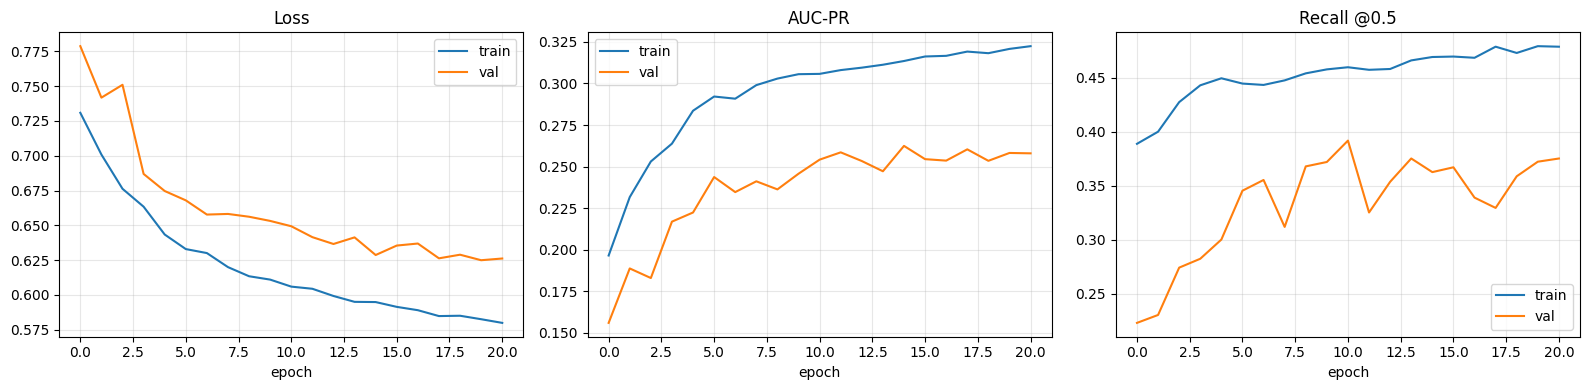

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (k, t) in zip(ax, [('loss','Loss'), ('auc_pr','AUC-PR'), ('recall','Recall @0.5')]):
    a.plot(history.history[k], label='train'); a.plot(history.history['val_' + k], label='val')
    a.set_title(t); a.set_xlabel('epoch'); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 7. Evaluation on the **test** set
Steps: (1) collect predictions, (2) pick the best threshold on the **eval** set (by F1), (3) report test metrics at that threshold, (4) compare with a trivial **persistence baseline** (predict that tomorrow's fire = today's fire).

In [ ]:
def collect(ds):
    probs, ys, ms, prevs = [], [], [], []
    for x, y in ds:
        probs.append(model.predict_on_batch(x)[..., 0])
        ys.append(y[..., 0].numpy()); ms.append(y[..., 1].numpy())
        prevs.append(x[..., N_CONT].numpy())            # prev-fire channel
    return [np.concatenate(a) for a in (probs, ys, ms, prevs)]

def scores(p_bin, y, m):
    v = m > 0
    pred, y = p_bin[v] > 0.5, y[v] > 0.5
    tp = (pred & y).sum(); fp = (pred & ~y).sum(); fn = (~pred & y).sum()
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    f1 = 2 * prec * rec / max(prec + rec, 1e-9); iou = tp / max(tp + fp + fn, 1)
    return dict(precision=prec, recall=rec, f1=f1, iou=iou)

pe, ye, me, _  = collect(eval_ds)
pt, yt, mt, prev_t = collect(test_ds)

# best threshold from the eval set
ths = np.linspace(0.05, 0.95, 37)
f1s = [scores((pe >= t).astype(np.float32), ye, me)['f1'] for t in ths]
best_t = ths[int(np.argmax(f1s))]
print(f'Best threshold on eval set: {best_t:.2f}  (F1 = {max(f1s):.4f})')

v = mt > 0
res = {
  'Attention U-Net (tuned thr.)': scores((pt >= best_t).astype(np.float32), yt, mt),
  'Attention U-Net (thr. 0.5)'  : scores((pt >= 0.5).astype(np.float32), yt, mt),
  'Persistence baseline'        : scores(prev_t, yt, mt),
}
ap = average_precision_score(yt[v] > 0.5, pt[v])

print(f"\n{'Model':32s} {'Prec':>7s} {'Recall':>7s} {'F1':>7s} {'IoU':>7s}")
for k, r in res.items():
    print(f"{k:32s} {r['precision']:7.4f} {r['recall']:7.4f} {r['f1']:7.4f} {r['iou']:7.4f}")
print(f'\nTest AUC-PR (average precision): {ap:.4f}')

Best threshold on eval set: 0.30  (F1 = 0.3601)

Model                               Prec  Recall      F1     IoU
Attention U-Net (tuned thr.)      0.3373  0.5115  0.4065  0.2551
Attention U-Net (thr. 0.5)        0.3702  0.4672  0.4131  0.2603
Persistence baseline              0.3572  0.2728  0.3093  0.1830

Test AUC-PR (average precision): 0.3132


## 8. Visual results

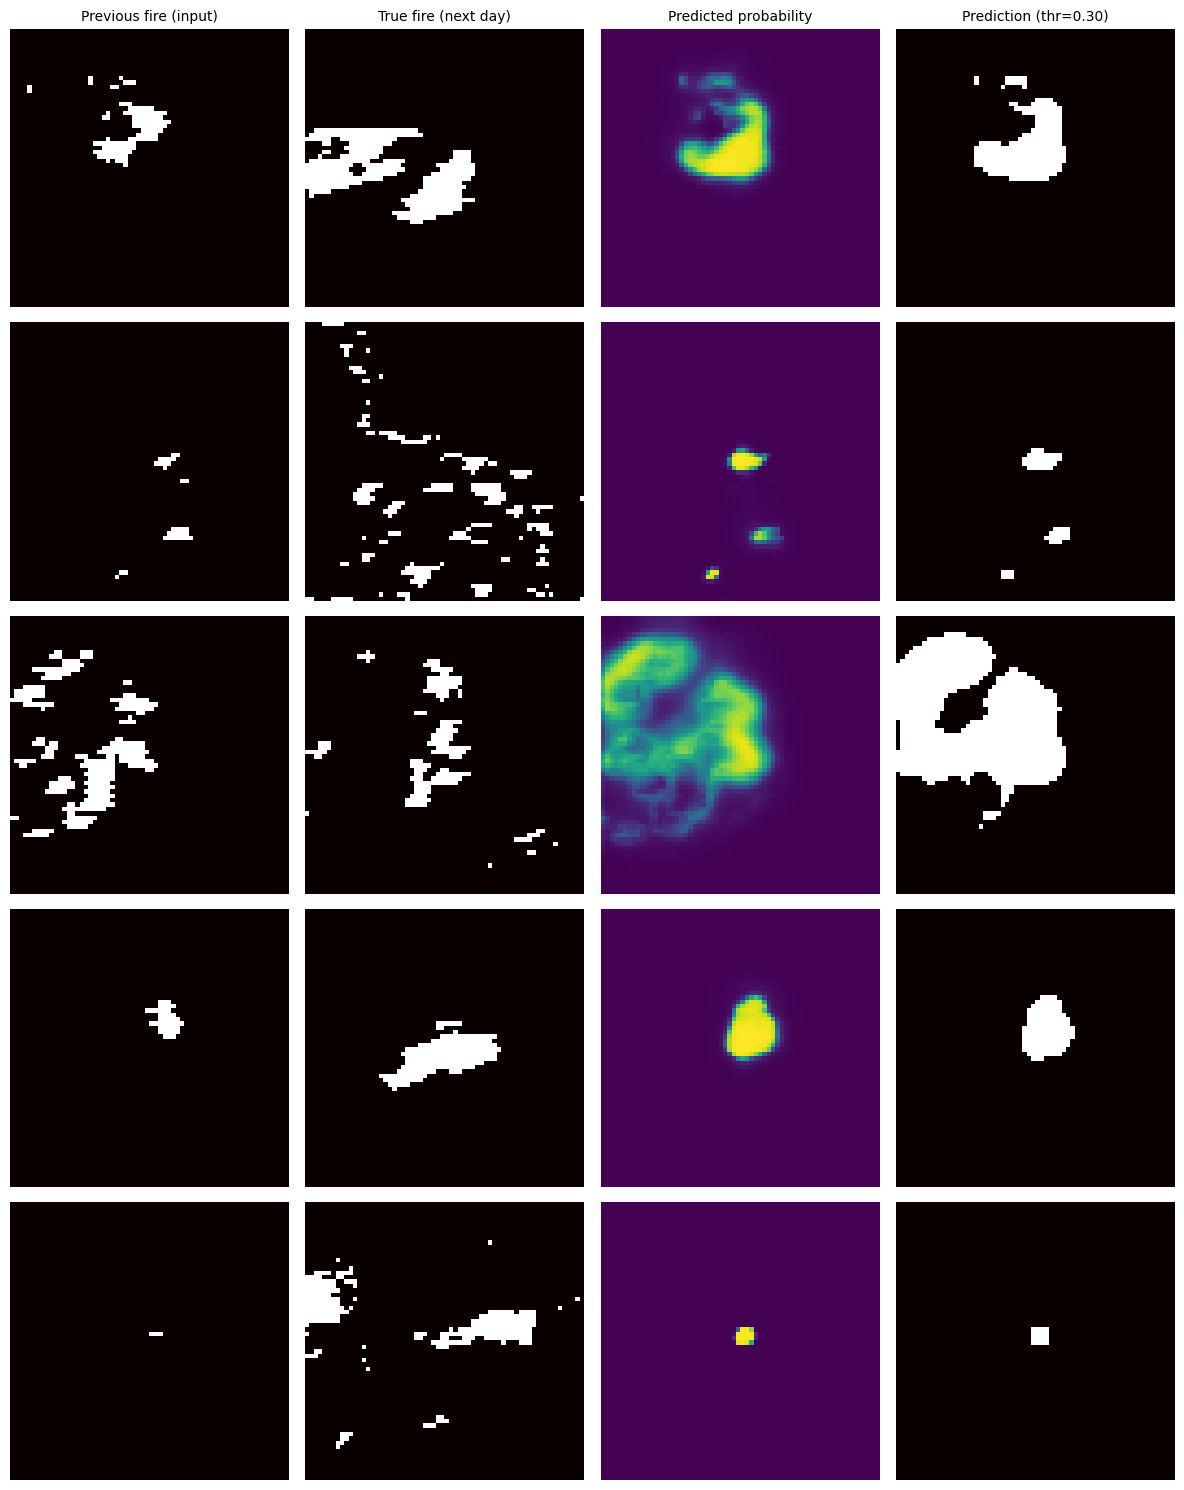

In [ ]:
idx = np.argsort(-(yt * mt).sum((1, 2)))[:200]          # samples that actually contain fire
idx = np.random.RandomState(0).choice(idx, 5, replace=False)

fig, ax = plt.subplots(len(idx), 4, figsize=(12, 3 * len(idx)))
titles = ['Previous fire (input)', 'True fire (next day)', 'Predicted probability', f'Prediction (thr={best_t:.2f})']
for r, i in enumerate(idx):
    imgs = [prev_t[i], np.where(mt[i] > 0, yt[i], np.nan), pt[i], (pt[i] >= best_t).astype(float)]
    for c in range(4):
        ax[r, c].imshow(imgs[c], cmap='hot' if c != 2 else 'viridis', vmin=0, vmax=1)
        ax[r, c].axis('off')
        if r == 0: ax[r, c].set_title(titles[c], fontsize=10)
plt.tight_layout(); plt.show()

In [ ]:
model.save(os.path.join(OUT_DIR, 'final_attention_unet.keras'))
print('Saved to', OUT_DIR)

Saved to /content/drive/MyDrive/Colab Notebooks/wildfire_outputs


In [ ]:
valid = mt > 0
acc_model = ((pt >= 0.5) == (yt > 0.5))[valid].mean()
acc_persist = ((prev_t > 0.5) == (yt > 0.5))[valid].mean()
acc_nofire = (yt[valid] <= 0.5).mean()
print(f"Model accuracy       : {acc_model*100:.2f}%")
print(f"Persistence accuracy : {acc_persist*100:.2f}%")
print(f"Always 'no fire'     : {acc_nofire*100:.2f}%")

## Notes for your report / viva
* **Dataset:** Next Day Wildfire Spread (Huot et al.), 64x64 km tiles at 1 km resolution; fire pixels are about 1% of valid pixels (severe class imbalance).
* **Why U-Net:** fire spread depends on context (wind, slope, fuel) far from a pixel, and a 3x3-only CNN cannot see it. The encoder/decoder gives a wide receptive field while skip connections keep fine detail.
* **Why masking:** pixels labeled -1 are unknown. Treating them as labels (as in the baseline) corrupts the loss and gives negative values.
* **Why AUC-PR and not accuracy:** predicting all "no fire" already gives about 99% accuracy.
* **Ablations to try:** `AUGMENT=False`, `dice_weight=0`, remove attention gates, `base=16` or `64`.